# Practical 7: Support Vector Machines (Linear and Non-linear Kernels)

**Aim:** Use SVM classifiers with linear and non-linear kernels and compare their performance.

**Datasets:** Breast Cancer (compare 4 kernels), Iris (draw boundaries), moons (data that a straight line cannot separate).

**Steps:** 1) Compare kernels on Breast Cancer  2) Draw decision boundaries  3) Linear vs RBF on moons  4) Effect of gamma  5) Tune C and gamma

## Step 1: Compare kernels on Breast Cancer

    Kernel  Accuracy  Precision  Recall     F1
0   linear     0.958      1.000   0.887  0.940
1     poly     0.895      1.000   0.717  0.835
2      rbf     0.972      1.000   0.925  0.961
3  sigmoid     0.951      0.979   0.887  0.931


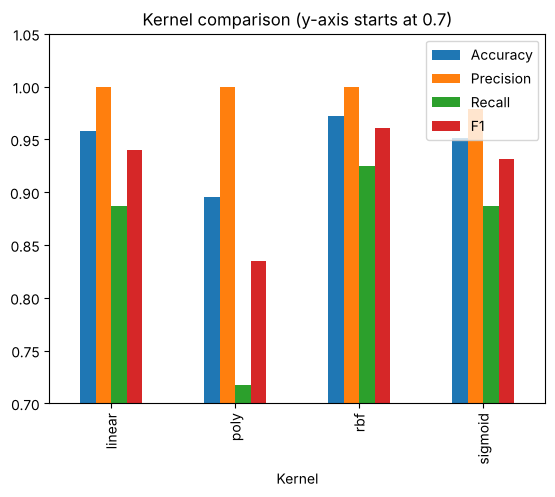

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_iris, make_moons
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

data = load_breast_cancer()
X = data.data
y = 1 - data.target          # 1 = malignant, 0 = benign

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

# SVM needs scaled data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

rows = []
for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    model = SVC(kernel=kernel)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append([kernel,
                 round(accuracy_score(y_test, pred), 3),
                 round(precision_score(y_test, pred), 3),
                 round(recall_score(y_test, pred), 3),
                 round(f1_score(y_test, pred), 3)])

table = pd.DataFrame(rows, columns=["Kernel", "Accuracy", "Precision", "Recall", "F1"])
print(table)

table.set_index("Kernel")[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar")
plt.ylim(0.7, 1.05)
plt.title("Kernel comparison (y-axis starts at 0.7)")
plt.show()

**How to read:** in my run **RBF was best (accuracy about 0.97)**, **linear was close (0.96)**, sigmoid about 0.95 and **polynomial was the weakest (about 0.90, low recall)**. The test set is small (143 patients), so linear vs RBF differ by only 2 patients: treat them as equal. Breast Cancer is almost linearly separable, so a non-linear kernel is not needed here.

## Step 2: Decision boundaries on Iris
We use only 2 features (petal length and width) so we can draw them. The coloured areas show the class the model predicts, and the **circled points are the support vectors**.

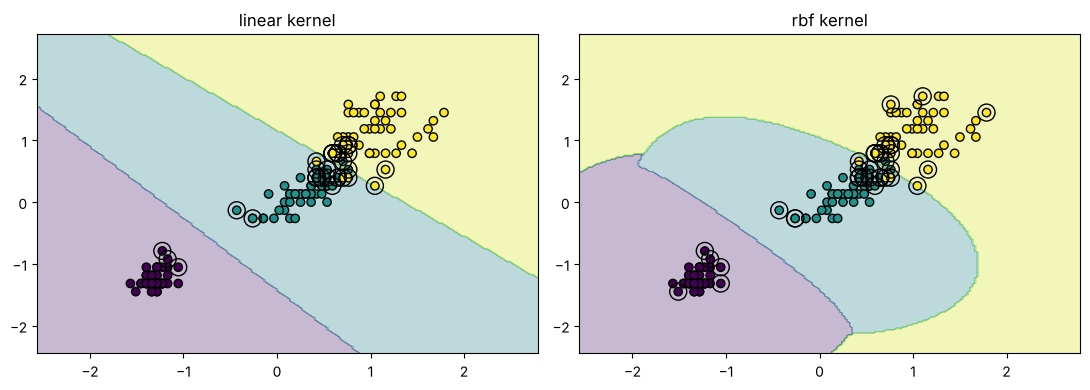

In [2]:
# Helper: draw the decision boundary of a model on a 2-feature dataset
def plot_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.contourf(xx, yy, Z, alpha=0.3)                       # coloured regions
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolor="k")        # the data points
    plt.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
                s=150, facecolors="none", edgecolors="black")  # circle the support vectors
    plt.title(title)

iris = load_iris()
Xi = StandardScaler().fit_transform(iris.data[:, 2:4])
yi = iris.target

plt.figure(figsize=(11, 4))
for i, kernel in enumerate(["linear", "rbf"]):
    model = SVC(kernel=kernel).fit(Xi, yi)
    plt.subplot(1, 2, i + 1)
    plot_boundary(model, Xi, yi, kernel + " kernel")
plt.tight_layout()
plt.show()

**How to read:** the border between two colours is the **decision boundary**. A dot in the wrong colour is a mistake. The **linear** kernel draws straight lines, the **RBF** kernel draws smooth curves. On Iris both work well because the species are well separated. The circled points (support vectors) are the points closest to the boundary: only they decide where it goes.

## Step 3: When a straight line is not enough (moons)

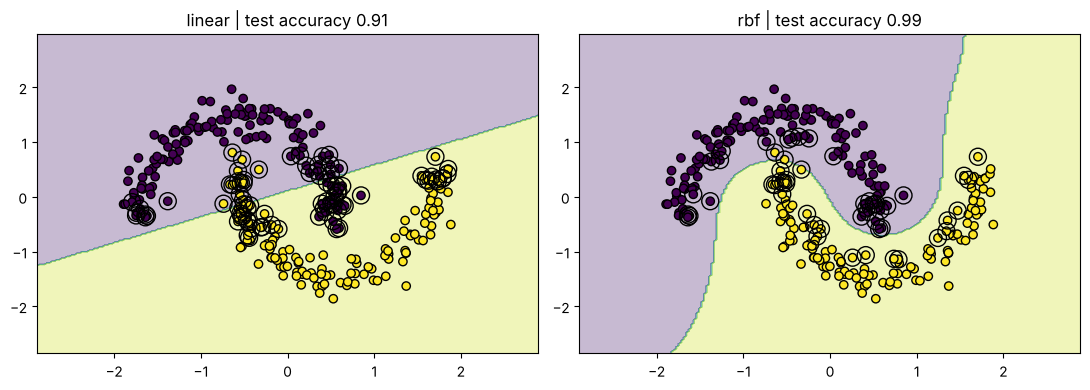

In [3]:
Xm, ym = make_moons(n_samples=400, noise=0.1, random_state=0)
Xm = StandardScaler().fit_transform(Xm)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(Xm, ym, test_size=0.3, random_state=0, stratify=ym)

plt.figure(figsize=(11, 4))
for i, kernel in enumerate(["linear", "rbf"]):
    model = SVC(kernel=kernel).fit(Xm_train, ym_train)
    acc = model.score(Xm_test, ym_test)
    plt.subplot(1, 2, i + 1)
    plot_boundary(model, Xm_train, ym_train, kernel + " | test accuracy " + str(round(acc, 2)))
plt.tight_layout()
plt.show()

**How to read:** the two moons curve around each other, so no straight line can separate them. The **linear** kernel cuts through both moons and gets about 9% wrong (test accuracy about 0.91). The **RBF** kernel bends the boundary around each moon (accuracy about 0.99). This is the **kernel trick**: RBF behaves as if the data was moved into a higher dimension where a straight separator exists.

## Step 4: Effect of gamma (RBF kernel)
`gamma` says how far the influence of one point reaches. Small gamma: far reach, smooth boundary. Large gamma: each point only affects its neighbours, giving tiny islands. We use noisier data (noise 0.3) so overfitting is easy to see.

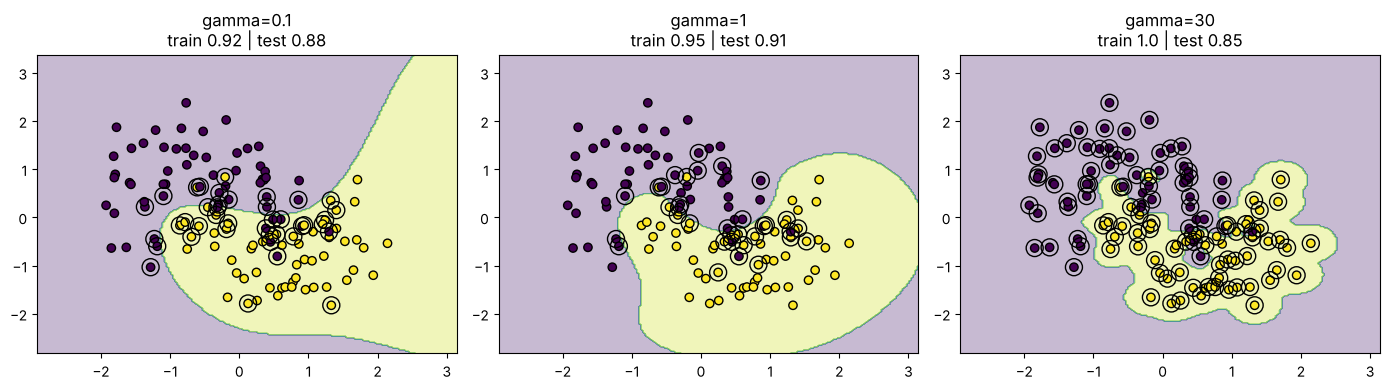

In [4]:
Xn, yn = make_moons(n_samples=200, noise=0.3, random_state=1)
Xn = StandardScaler().fit_transform(Xn)
Xn_train, Xn_test, yn_train, yn_test = train_test_split(Xn, yn, test_size=0.4, random_state=1, stratify=yn)

plt.figure(figsize=(14, 4))
for i, gamma in enumerate([0.1, 1, 30]):
    model = SVC(kernel="rbf", C=100, gamma=gamma).fit(Xn_train, yn_train)
    train_acc = model.score(Xn_train, yn_train)
    test_acc = model.score(Xn_test, yn_test)
    plt.subplot(1, 3, i + 1)
    plot_boundary(model, Xn_train, yn_train,
                  "gamma=" + str(gamma) + "\ntrain " + str(round(train_acc, 2)) + " | test " + str(round(test_acc, 2)))
plt.tight_layout()
plt.show()

**How to read:**
- **gamma = 0.1 (small):** very smooth boundary, the lowest train accuracy (about 0.92) = **underfitting** (too simple).
- **gamma = 1 (medium):** a smooth curve that follows the moons, the best test accuracy = good balance.
- **gamma = 30 (large):** tiny islands around single points, train accuracy 1.00 but test accuracy drops = **overfitting**.

`C` works in a similar way: a very large C also tries to get every training point right (overfitting), a small C allows some mistakes (smoother).

## Step 5: Tune C and gamma with GridSearchCV

In [5]:
param_grid = {"C": [0.1, 1, 10, 100], "gamma": [0.001, 0.01, 0.1, 1]}

grid = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=5)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation accuracy:", round(grid.best_score_, 3))
print("Test accuracy:", round(grid.score(X_test, y_test), 3))

Best parameters: {'C': 10, 'gamma': 0.01}
Best cross-validation accuracy: 0.979
Test accuracy: 0.979


`GridSearchCV` tries every combination of C and gamma with cross-validation and keeps the best one.

## Conclusion
On Breast Cancer, linear and RBF kernels work about equally well, because the data is nearly linearly separable. On the moons data, a straight line fails and RBF works very well. SVM needs scaled data, and C and gamma control underfitting vs overfitting: tune them with cross-validation.

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is an SVM?**
A supervised algorithm that finds the hyperplane separating the classes with the **maximum margin**. It is used for classification (SVC) and regression (SVR).

**Q2. What is a hyperplane?**
A decision surface of dimension n-1 in n-dimensional space: a line in 2D, a plane in 3D.

**Q3. What are support vectors?**
The training points closest to the hyperplane (on or inside the margin). They alone determine its position; removing other points does not change it.

**Q4. What is the margin and why maximise it?**
The distance between the hyperplane and the nearest points of each class. A larger margin gives better generalisation and lower risk of overfitting.

**Q5. Hard margin vs soft margin?**
Hard margin allows no misclassification and needs perfectly separable data. Soft margin allows some violations, controlled by C, so it works with noisy, overlapping data.

**Q6. What does C control?**
The trade-off between a wide margin and training errors. Large C: fewer training errors, narrow margin, overfitting risk. Small C: wide margin, more errors allowed, underfitting risk.

**Q7. What is the kernel trick?**
Computing the dot product of data in a higher-dimensional space directly with a kernel function, without actually transforming the data. It lets SVM learn non-linear boundaries cheaply.

**Q8. Name the common kernels and when to use them.**
Linear: $K=x^Tz$, for linearly separable or high-dimensional sparse data (text). Polynomial: $K=(\gamma x^Tz+r)^d$, for curved boundaries. RBF (Gaussian): $K=\exp(-\gamma\|x-z\|^2)$, the default for general non-linear data. Sigmoid: $K=\tanh(\gamma x^Tz+r)$, rarely used.

**Q9. What is gamma in the RBF kernel?**
It controls how far a single training point's influence reaches. High gamma: small influence, complex boundary, overfitting. Low gamma: large influence, smooth boundary, underfitting.

**Q10. Why must features be scaled for SVM?**
SVM uses distances, so large-range features would dominate the margin and kernel calculation.

**Q11. How does SVM do multi-class classification?**
By combining binary classifiers: one-vs-one (scikit-learn's SVC) or one-vs-rest.

**Q12. Advantages and disadvantages of SVM?**
Advantages: effective in high dimensions, robust when a clear margin exists, memory-efficient (uses only support vectors), flexible via kernels. Disadvantages: slow on very large datasets, needs scaling and tuning, no direct probabilities (`probability=True` adds cost), and performs poorly with heavy noise or overlapping classes.

**Q13. Linear SVM vs logistic regression?**
Both are linear classifiers. SVM maximises the margin using hinge loss and depends only on support vectors; logistic regression uses log loss, gives probabilities and uses all points.

**Q14. What is hinge loss?**
$\max(0, 1 - y f(x))$: zero for points correctly classified beyond the margin, growing linearly for violations.

**Q15. How do you choose the kernel and parameters?**
Start with linear and RBF, then tune C and gamma with GridSearchCV and cross-validation.

**Q16. Why did linear and RBF give similar accuracy on Breast Cancer?**
The data is almost linearly separable, so a complex kernel adds no benefit. Non-linear kernels help only when the classes are not linearly separable.

**Q16b. Which kernel did best and worst in your run, and why?**
RBF was best (0.972) with linear close behind (0.958); polynomial was worst (0.895, recall 0.72). The default degree-3 polynomial kernel is sensitive to scaling and its settings (`degree`, `coef0`), so it needs tuning. The linear-vs-RBF gap is only 2 patients on 143 test samples, so it is not significant.

**Q17. What is the difference between `SVC` and `LinearSVC`?**
`SVC(kernel='linear')` uses libsvm (supports kernels, slower on big data). `LinearSVC` uses liblinear (linear only, much faster on large datasets).

**Q18. How do you get class probabilities from an SVM?**
Set `probability=True`; scikit-learn fits Platt scaling using internal cross-validation (slower).

**Q19. What does the "dual form" of SVM mean?**
The optimisation is written in terms of Lagrange multipliers, where only support vectors have non-zero multipliers, and the data appears only through dot products, which is what makes the kernel trick possible.

**Q20. Is SVM sensitive to outliers?**
A hard-margin SVM is; a soft-margin SVM with smaller C is more robust.

**Q21. What is `gamma='scale'`?**
The default $\gamma = 1/(n_{features}\cdot Var(X))$, which adapts to the data scale.

## B. Questions about the graphs

**G1. What does the decision boundary plot show?**
Coloured regions show the class predicted at each point in the plane; the boundary between colours is the decision boundary. Points are the data coloured by true class; points in the wrong region are misclassified.

**G2. How does the linear boundary differ from the RBF boundary?**
Linear gives straight lines (hyperplanes); RBF gives smooth, curved, flexible regions that wrap around clusters.

**G3. What are the circled points?**
Support vectors.

**G4. Why does the linear kernel fail on the moons data?**
The classes are interleaved and not linearly separable, so no straight line can separate them. RBF bends the boundary around the moons.

**G5. What would a very high gamma look like?**
Tiny islands around individual points (very wiggly boundary): overfitting. A very low gamma gives an almost straight boundary: underfitting.

**G6. What if C is very large?**
The model tries to classify every training point correctly: narrow margin and possible overfitting. Small C gives a wider margin that allows some errors (more generalisation).

## C. Code questions

**C1. Why scale before SVM, and why fit the scaler on training data only?**
SVM is distance-based; fitting on train only avoids data leakage.

**C3. What does `GridSearchCV` do?**
Tries every combination in the parameter grid with cross-validation and keeps the best.

**C4. What does `np.meshgrid` do in the boundary plot?**
Creates a grid of points covering the plane; the model predicts a class for each, and `contourf` colours the regions.